# MNIST MLP — Kaggle Notebook training (executed run)

The actual run, outputs intact. Run 2026-08-01: baseline → Optuna search (20 trials) → retrain of the winning config → final test evaluation. To rerun it, upload this notebook to Kaggle, do the setup below, then **Run all** (the outputs are overwritten).

**Before running this notebook**, in the Kaggle UI:
1. Go to your published dataset's page (`kaggle.com/datasets/<you>/mnist-mlp-pipeline`) and use its **⋮ menu → New notebook** — this attaches the dataset automatically. (Searching for a private dataset from inside an existing notebook's "Add Input" can be unreliable / laggy to index.)
2. In that notebook, **Add Input** → search `digit-recognizer` → add the card with the trophy icon, marked "Ongoing" / "Getting Started" (not the similarly-named community datasets below it).
3. **Settings → Accelerator → GPU T4 x2** (or P100). Requires phone-verifying your Kaggle account once, if you haven't already.
4. **Settings → Environment Preferences → Internet → On** (needed for the `pip install` cell below).

**Note on input paths**: this Kaggle environment nests inputs rather than using the flat `/kaggle/input/<slug>/` layout some older docs describe:
- Datasets mount at `/kaggle/input/datasets/<owner>/<dataset-slug>/`
- Competitions mount at `/kaggle/input/competitions/<competition-slug>/`

The cells below already use these paths. Kaggle also auto-extracts the uploaded `src.zip`/`configs.zip` into real folders — no unzip step needed, just add the dataset path to `sys.path`.

Re-run `scripts/publish_kaggle_dataset.py` locally and re-add/update the input whenever `src/` or `configs/` changes — Kaggle datasets don't auto-sync with local edits.

In [2]:
!pip install -q pytorch-lightning torchmetrics optuna python-dotenv

In [3]:
import os
import sys

DATASET_DIR = '/kaggle/input/datasets/ivannamor/mnist-mlp-pipeline'
print('src contents:', os.listdir(f'{DATASET_DIR}/src'))
print('configs contents:', os.listdir(f'{DATASET_DIR}/configs'))

sys.path.insert(0, DATASET_DIR)
print('project code ready')

src contents: ['train.py', 'evaluate.py', 'data_module.py', 'model.py', 'search.py', 'config.py', '__init__.py']
configs contents: ['baseline.yaml']
project code ready


In [4]:
from src.config import ExperimentConfig

config = ExperimentConfig.from_yaml('/kaggle/input/datasets/ivannamor/mnist-mlp-pipeline/configs/baseline.yaml')
config.data.data_dir = '/kaggle/input/competitions/digit-recognizer'
config.trainer.experiment_name = 'baseline'
config

ExperimentConfig(data=DataConfig(data_dir='/kaggle/input/competitions/digit-recognizer', train_csv='train.csv', val_fraction=0.2, test_fraction=0.2, batch_size=64, num_workers=2, seed=42), model=ModelConfig(hidden_dims=[256, 128, 64], activation='relu', dropout=0.25, num_classes=10), optim=OptimConfig(optimizer='adam', lr=0.001, weight_decay=0.0, label_smoothing=0.0, lr_scheduler=None), trainer=TrainerConfig(max_epochs=30, accelerator='auto', devices=1, patience=5, experiment_name='baseline'))

## Baseline training run (GPU)

In [5]:
from src.train import train

trainer = train(config)

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                  ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net                   │ Sequential                │  242 K │ train │     0 │
│ 1 │ loss_fn               │ CrossEntropyLoss          │      0 │ train │     0 │
│ 2 │ val_accuracy          │ MulticlassAccuracy        │      0 │ train │     0 │
│ 3 │ val_precision         │ MulticlassPrecision       │      0 │ train │     0 │
│ 4 │ val_recall            │ MulticlassRecall          │      0 │ train │     0 │
│ 5 │ test_accuracy         │ MulticlassAccuracy        │      0 │ train │     0 │
│ 6 │ test_precision        │ MulticlassPrecision       │      0 │ train │     0 │
│ 7 │ test_recall           │ MulticlassRecall          │      0 │ train │     0 │
│ 8 │ test_confusion_matrix │ MulticlassConfusionMatrix │      0 │ train │     0 │
└───┴───────────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 242 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 242 K                                                                                                
Total estimated model params size (MB): 0.971                                                                      
Modules in train mode: 19                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

Best val_accuracy: 0.971924901008606
Best checkpoint: outputs/logs/baseline/version_0/checkpoints/best.ckpt


## Hyperparameter search (Optuna)

Reuses `search.objective`, pointed at the same Kaggle data path. When rerunning, start with a small `n_trials` to gauge how long each trial takes within the GPU quota. No checkpoints are saved per trial (kept lightweight) — only the winning hyperparameters come out of this step; the next cell retrains that configuration for real.

In [6]:
import optuna
from src.search import objective

study = optuna.create_study(direction='maximize', pruner=optuna.pruners.MedianPruner())
study.optimize(lambda trial: objective(trial, config), n_trials=20)

print('Best value:', study.best_value)
print('Best params:', study.best_params)

[I 2026-08-01 15:00:56,882] A new study created in memory with name: no-name-ca707af7-ee31-41d6-82d2-ceea244b4072
Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                  ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net                   │ Sequential                │  235 K │ train │     0 │
│ 1 │ loss_fn               │ CrossEntropyLoss          │      0 │ train │     0 │
│ 2 │ val_accuracy          │ MulticlassAccuracy        │      0 │ train │     0 │
│ 3 │ val_precision         │ MulticlassPrecision       │      0 │ train │     0 │
│ 4 │ val_recall            │ MulticlassRecall          │      0 │ train │     0 │
│ 5 │ test_accuracy         │ MulticlassAccuracy        │      0 │ train │     0 │
│ 6 │ test_precision        │ MulticlassPrecision       │      0 │ train │     0 │
│ 7 │ test_recall           │ MulticlassRecall          │      0 │ train │     0 │
│ 8 │ test_confusion_matrix │ MulticlassConfusionMatrix │      0 │ train │     0 │
└───┴───────────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 235 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 235 K                                                                                                
Total estimated model params size (MB): 0.941                                                                      
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
[I 2026-08-01 15:02:57,549] Trial 0 finished with value: 0.9608739614486694 and parameters: {'hidden_dims': 'small', 'activation': 'relu', 'dropout': 0.33918077894156173, 'optimizer': 'adam', 'lr': 0.001420167567679641, 'weight_decay': 0.0008016696645612812, 'label_smoothing': 0.0, 'batch_size': 32}. Best is trial 0 with value: 0.9608739614486694.
Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable L

┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                  ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net                   │ Sequential                │  235 K │ train │     0 │
│ 1 │ loss_fn               │ CrossEntropyLoss          │      0 │ train │     0 │
│ 2 │ val_accuracy          │ MulticlassAccuracy        │      0 │ train │     0 │
│ 3 │ val_precision         │ MulticlassPrecision       │      0 │ train │     0 │
│ 4 │ val_recall            │ MulticlassRecall          │      0 │ train │     0 │
│ 5 │ test_accuracy         │ MulticlassAccuracy        │      0 │ train │     0 │
│ 6 │ test_precision        │ MulticlassPrecision       │      0 │ train │     0 │
│ 7 │ test_recall           │ MulticlassRecall          │      0 │ train │     0 │
│ 8 │ test_confusion_matrix │ MulticlassConfusionMatrix │      0 │ train │     0 │
└───┴───────────────────────┴───────────────────────────┴────────┴───────┴───────┘

...

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
[I 2026-08-01 15:22:04,183] Trial 18 finished with value: 0.9738426208496094 and parameters: {'hidden_dims': 'wide', 'activation': 'relu', 'dropout': 0.1976093328185669, 'optimizer': 'adamw', 'lr': 0.002940071370033726, 'weight_decay': 0.0004137906827528767, 'label_smoothing': 0.1, 'batch_size': 128}. Best is trial 17 with value: 0.9786615371704102.
Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable

┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                  ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net                   │ Sequential                │  535 K │ train │     0 │
│ 1 │ loss_fn               │ CrossEntropyLoss          │      0 │ train │     0 │
│ 2 │ val_accuracy          │ MulticlassAccuracy        │      0 │ train │     0 │
│ 3 │ val_precision         │ MulticlassPrecision       │      0 │ train │     0 │
│ 4 │ val_recall            │ MulticlassRecall          │      0 │ train │     0 │
│ 5 │ test_accuracy         │ MulticlassAccuracy        │      0 │ train │     0 │
│ 6 │ test_precision        │ MulticlassPrecision       │      0 │ train │     0 │
│ 7 │ test_recall           │ MulticlassRecall          │      0 │ train │     0 │
│ 8 │ test_confusion_matrix │ MulticlassConfusionMatrix │      0 │ train │     0 │
└───┴───────────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 535 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 535 K                                                                                                
Total estimated model params size (MB): 2.143                                                                      
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
`Trainer.fit` stopped: `max_epochs=30` reached.
[I 2026-08-01 15:22:58,373] Trial 19 finished with value: 0.8098245859146118 and parameters: {'hidden_dims': 'wide', 'activation': 'tanh', 'dropout': 0.3400077531200592, 'optimizer': 'sgd', 'lr': 0.0010770925858074175, 'weight_decay': 0.00015505974799390665, 'label_smoothing': 0.1, 'batch_size': 128}. Best is trial 17 with value: 0.9786615371704102.


Best value: 0.9786615371704102
Best params: {'hidden_dims': 'wide', 'activation': 'gelu', 'dropout': 0.258885920517189, 'optimizer': 'adamw', 'lr': 0.0009157770842261716, 'weight_decay': 0.00043489682497903484, 'label_smoothing': 0.1, 'batch_size': 128}


## Retrain the winning configuration

The search above only reports the best hyperparameters, not a saved model. This retrains that exact configuration once, with checkpointing on, to get the model that the final evaluation runs against.

In [7]:
from src.search import build_config

best_config = build_config(study.best_params, config)
best_config.trainer.experiment_name = 'best_from_search'
best_trainer = train(best_config)

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                  ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net                   │ Sequential                │  535 K │ train │     0 │
│ 1 │ loss_fn               │ CrossEntropyLoss          │      0 │ train │     0 │
│ 2 │ val_accuracy          │ MulticlassAccuracy        │      0 │ train │     0 │
│ 3 │ val_precision         │ MulticlassPrecision       │      0 │ train │     0 │
│ 4 │ val_recall            │ MulticlassRecall          │      0 │ train │     0 │
│ 5 │ test_accuracy         │ MulticlassAccuracy        │      0 │ train │     0 │
│ 6 │ test_precision        │ MulticlassPrecision       │      0 │ train │     0 │
│ 7 │ test_recall           │ MulticlassRecall          │      0 │ train │     0 │
│ 8 │ test_confusion_matrix │ MulticlassConfusionMatrix │      0 │ train │     0 │
└───┴───────────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 535 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 535 K                                                                                                
Total estimated model params size (MB): 2.143                                                                      
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

`Trainer.fit` stopped: `max_epochs=30` reached.


Best val_accuracy: 0.9811789989471436
Best checkpoint: outputs/logs/best_from_search/version_0/checkpoints/best.ckpt


## Final test-set evaluation

Run once, after the retrain above — not per trial. This is the number that was reported.

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test_accuracy       │    0.9829992055892944     │
│         test_loss         │    0.5549116134643555     │
│      test_precision       │    0.9829310178756714     │
│        test_recall        │    0.9829992055892944     │
└───────────────────────────┴───────────────────────────┘

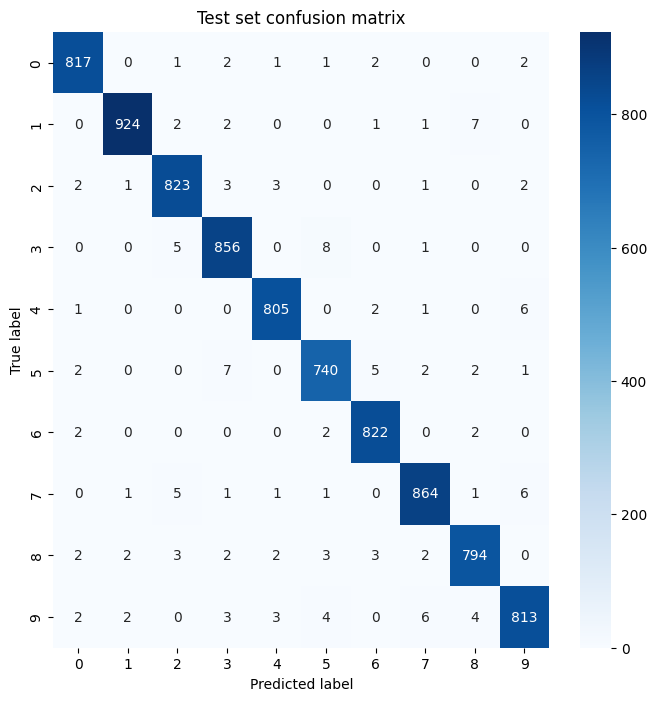

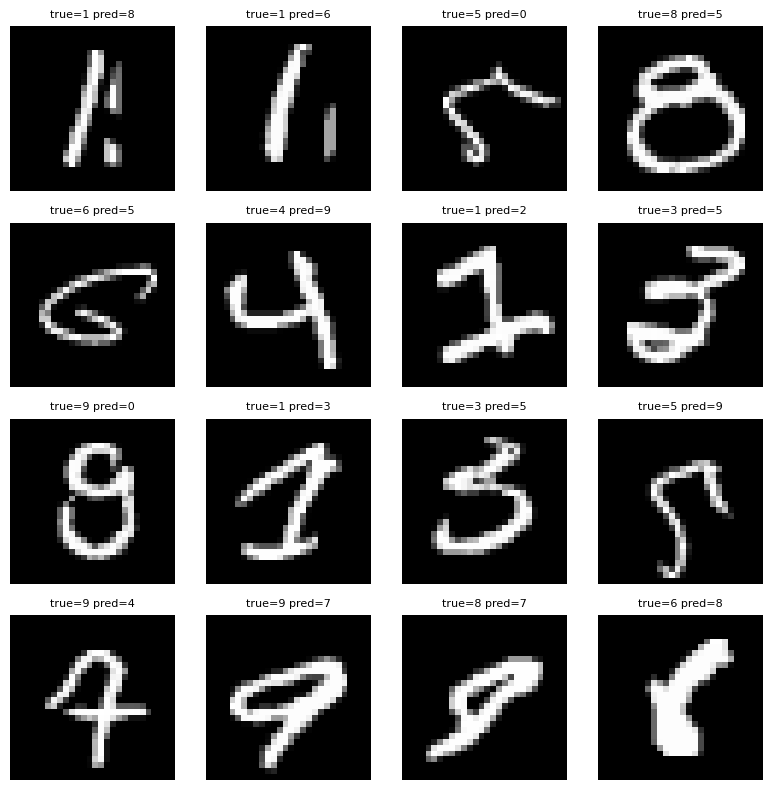

In [8]:
from pathlib import Path
from src.evaluate import evaluate

checkpoint_path = best_trainer.checkpoint_callback.best_model_path
evaluate(best_config, checkpoint_path, Path('/kaggle/working/evaluation'))